In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

import FlightTimeModel as ftm
from FlightTimeModel import Drone

# Configuration Setup
MOTOR = dict(
    kv=1088.0,        # rpm/V
    i0=0.4,           # zero-load current (A)
    r_motor=0.232,    # internal resistance of one motor (ohm)
    r_esc=0.015,       # internal resistance of one ESC (ohm)
)

BATTERY = dict(
    cell_voltage=3.7,       # voltage of one cell, constant (V)
    n_cells=3,              # number of cells in pack
    r_cell=0.005,           # internal resistance of one cell (ohm)
    capacity_ah=2.2,        # total amp-hours in pack (Ah)
    usable_fraction=0.8,     # reserve 20% of battery for optimal usage
)

PROP = dict(
    prop_diameter_m=9 * 0.0254, # 9 inch prop
    rpm=None,
    ct=None,
    cp=None,
)

N_MOTORS = 4

# Mission Definition
MISSION = [
    ("takeoff/climb", 1.10, 3),
    ("hover 2 min",   1.00, 120),
    ("circle 1 min",  1.00, 60),
    ("accel leg 1",   1.02, 3),
    ("cruise leg 1",  1.00, 5),
    ("hover/yaw",     1.00, 6),
    ("leg 2",         1.00, 10),
    ("main descent",  0.90, 5),
    ("descent 1cm/s", 0.98, 10),
]

WEIGHT_RANGE_KG = (0.5, 3.0)
N_POINTS = 26
MAKE_PLOT = True

In [22]:
if PROP["rpm"] is not None: # swap prop tables in model module
    ftm.PROP_RPM = np.asarray(PROP["rpm"], float)
    ftm.PROP_CT = np.asarray(PROP["ct"], float)
    ftm.PROP_CP = np.asarray(PROP["cp"], float)

def make_drone(weight_kg):
    return Drone(
        weight_kg=weight_kg,
        n_motors=N_MOTORS,
        prop_diameter_m=PROP["prop_diameter_m"],
        **MOTOR,
        **BATTERY
    )

def mission_charge_ah(weight_kg):
    d = make_drone(weight_kg)
    try:
        return sum(d.segment(twr,t)["charge_Ah"] for _,twr,t in MISSION)
    except ValueError:
        return np.nan

def feasible(weight_kg):
    return not np.isnan(mission_charge_ah(weight_kg))

def find_limits():
    usable = BATTERY["capacity_ah"] * BATTERY["usable_fraction"]
    w_lo, w_hi = WEIGHT_RANGE_KG
    # Heaviest weight at which the mission is still flyable
    if feasible(w_hi):
        w_throttle = w_hi
    else:
        lo,hi = w_lo,w_hi
        for _ in range(60):
            mid = 0.5*(lo+hi)
            lo,hi = (mid,hi) if feasible(mid) else (lo,mid)
        w_throttle = lo
    # Weight where mission charge == usable capacity, bounded by w_throttle
    f = lambda w: mission_charge_ah(w) - usable
    if f(w_lo) > 0: 
        w_batt = None # over budget at lightest weight
    elif f(w_throttle) < 0:
        w_batt = None # never reaches cutoff before throttle runs out
    else:
        w_batt = brentq(f,w_lo,w_throttle,xtol=1e-5)
    return usable, w_batt, w_throttle



Mission: 222 s | battery 3S 2.2 Ah, usable 1.76 Ah (80%)

 weight kg  charge Ah  % usable  hover min  I_pack hover
      0.50      0.247        14       26.3           4.0
      0.60      0.292        17       22.3           4.7
      0.70      0.367        21       17.7           6.0
      0.80      0.450        26       14.5           7.3
      0.90      0.538        31       12.1           8.7
      1.00      0.636        36       10.2          10.3
      1.10      0.741        42        8.8          12.0
      1.20      0.853        48        7.6          13.9
      1.30      0.974        55        6.7          15.8
      1.40      1.103        63        5.9          17.9
      1.50      1.238        70        5.2          20.1
      1.60      1.383        79        4.7          22.5
      1.70      1.538        87        4.2          25.0
      1.80      1.696        96        3.8          27.6
      1.90      1.861       106        3.5          30.2
      2.00      2.041       11

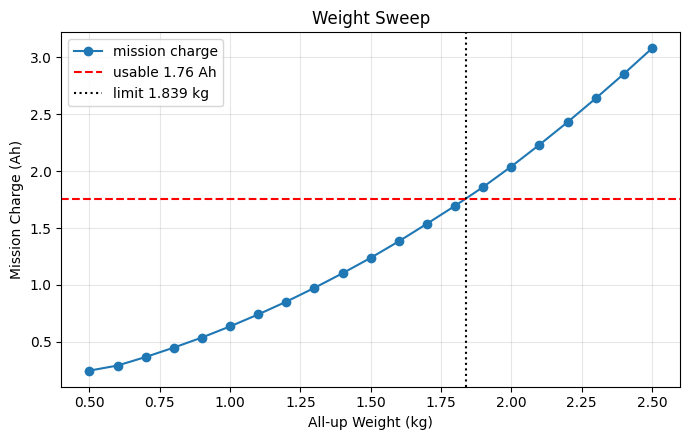

In [25]:
usable, w_batt, w_throttle = find_limits()
mission_s = sum(t for _,_,t in MISSION)
print(f'Mission: {mission_s:.0f} s | battery {BATTERY["n_cells"]}S {BATTERY["capacity_ah"]} Ah, '
      f'usable {usable:.2f} Ah ({BATTERY["usable_fraction"]*100:.0f}%)\n')
weights = np.linspace(*WEIGHT_RANGE_KG, N_POINTS)
print(f'{'weight kg':>10}{'charge Ah':>11}{'% usable':>10}{'hover min':>11}{'I_pack hover':>14}')
charges = []
for w in weights:
    q = mission_charge_ah(w)
    charges.append(q)
    if np.isnan(q):
        print(f'{w:>10.2f}{'--':>11}{'not flyable (throttle > 100%)':>35}')
        continue
    d = make_drone(w)
    i_h = d.operating_point(1.0)["battery_current_A"]
    hover_min = usable / i_h * 60.0
    print(f"{w:>10.2f}{q:>11.3f}{100*q/usable:>10.0f}{hover_min:>11.1f}{i_h:>14.1f}")

print()
if w_batt is not None:
    d = make_drone(w_batt)
    pk = max(d.operating_point(twr)["motor_current_A"] for _,twr,_ in MISSION)
    pe = max(d.operating_point(twr)["esc_input_current_A"] for _,twr,_ in MISSION)
    print(f"80% CUTOFF WEIGHT = MTOW = {w_batt:.3f} kg")
    print(f"  at that weight, peak per-arm current: ESC->motor {pk:.2f} A, battery->ESC {pe:.2f} A")
else:
    print("No battery-limited weight inside the sweep range (see table).")
    print(f"Heaviest weight that is still flyable (throttle limit): {w_throttle:.3f} kg")

if MAKE_PLOT:
    fig, ax = plt.subplots(figsize=(7,4.5))
    ax.plot(weights, charges, "o-", label="mission charge")
    ax.axhline(usable, color="r", linestyle="--", label=f"usable {usable:.2f} Ah")
    if w_batt is not None:
        ax.axvline(w_batt, color="k", linestyle=":", label=f"limit {w_batt:.3f} kg")
    ax.set_xlabel("All-up Weight (kg)")
    ax.set_ylabel("Mission Charge (Ah)")
    ax.set_title("Weight Sweep")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig("weight_sweep.png", dpi=150)
    plt.show()
